# Semiconductor Volatility Modeling
### GARCH, Asymmetric Risk & CNN Forecast Evaluation

**Research question.** How effectively do conditional volatility models describe and forecast the risk of semiconductor equities, and can a small 1D-CNN improve on traditional benchmarks?

We study **NVIDIA (NVDA), AMD, Broadcom (AVGO), and Intel (INTC)** using adjusted daily prices from **January 2018 to September 2026**. We model the **magnitude of return fluctuations, not the direction of share prices**. The notebook combines exploratory diagnostics, maximum-likelihood GARCH estimation, genuine one-step-ahead forecasts, and a compact deep-learning comparison.

| Stage | Focus |
|---|---|
| 1 | Returns, volatility clustering, GARCH(1,1) |
| 2 | EGARCH, GJR-GARCH, Gaussian vs Student-t |
| 3 | Out-of-sample forecasting and benchmark comparison |
| 4 | 1D-CNN volatility forecasting |
| 5 | Forecast stability and research conclusions |

**Reading the results:** Stages 1–2 describe *in-sample* model behavior; Stages 3–5 evaluate *out-of-sample* forecasting performance. The reported findings refer to the saved run ending **18 September 2026** and may change when market data or model training changes.

---
## Stage 1 — Returns and the GARCH Baseline
We begin by downloading adjusted prices for a consistent four-stock sample, then compute percentage log returns.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from arch import arch_model
from scipy.stats import jarque_bera
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

# Research configuration 
TICKERS = ["NVDA", "AMD", "AVGO", "INTC"]

START_DATE = "2018-01-01"
END_DATE = "2026-09-21"  # Exclusive upper bound

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

print("Libraries imported successfully.")
print(f"Research universe: {', '.join(TICKERS)}")
print(f"Sample period: {START_DATE} to {END_DATE}")

Libraries imported successfully.
Research universe: NVDA, AMD, AVGO, INTC
Sample period: 2018-01-01 to 2026-09-21


### 1.1 — Adjusted stock prices
Adjusted close prices account for corporate actions reflected in the data provider's adjustment. We check the sample dates and missing observations before computing returns.

In [2]:
raw_data = yf.download(
    tickers=TICKERS,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False
)

# Extract adjusted closing prices
prices = raw_data["Close"][TICKERS].copy()
print("Price data shape:", prices.shape)
print("First observation:", prices.index.min().date())
print("Last observation:", prices.index.max().date())

print("\nMissing values per asset:")
print(prices.isna().sum())

display(prices.head())
display(prices.tail())

Price data shape: (2190, 4)
First observation: 2018-01-02
Last observation: 2026-09-18

Missing values per asset:
Ticker
NVDA    0
AMD     0
AVGO    0
INTC    0
dtype: int64


Ticker,NVDA,AMD,AVGO,INTC
Date,,,,
2018-01-02,4.917028,10.98,21.015072,39.330372
2018-01-03,5.240635,11.55,21.244894,37.995590
2018-01-04,5.268260,12.12,21.251980,37.298809
2018-01-05,5.312906,11.88,21.377905,37.559055
2018-01-08,5.475696,12.28,21.429062,37.559055


Ticker,NVDA,AMD,AVGO,INTC
Date,,,,
2026-09-14,210.960007,493.410004,344.093414,97.190002
2026-09-15,212.169998,504.200012,338.653320,97.139999
2026-09-16,213.899994,512.500000,338.892914,101.050003
2026-09-17,219.339996,545.090027,346.668732,108.800003
2026-09-18,222.270004,559.820007,356.959991,108.599998


### 1.2 — Daily log returns

\[r_t=100\log(P_t/P_{t-1})\]

Working with returns, rather than nominal prices, makes price changes comparable across stocks. Multiplication by 100 expresses daily returns in percentage points.

In [3]:

# Calculate daily log returns (%)
log_returns = 100 * np.log(prices / prices.shift(1))

# Remove first NaN observation
log_returns = log_returns.dropna()

# Validate returns
if not np.isfinite(log_returns.to_numpy()).all():
    raise ValueError("Log returns contain non-finite values.")

print("Log returns shape:", log_returns.shape)

print("\nDescriptive statistics:")
display(log_returns.describe().round(4))

display(log_returns.head())

Log returns shape: (2189, 4)

Descriptive statistics:


Ticker,NVDA,AMD,AVGO,INTC
count,2189.0000,2189.0000,2189.0000,2189.0000
mean,0.1741,0.1796,0.1294,0.0464
std,3.1704,3.5470,2.6262,3.0549
min,-20.7711,-19.0125,-22.2056,-30.1896
25%,-1.5120,-1.7227,-1.1411,-1.3113
50%,0.2645,0.0744,0.1387,0.0199
75%,1.9381,2.0668,1.4130,1.3921
max,21.8088,21.3663,21.8594,21.1879


Ticker,NVDA,AMD,AVGO,INTC
Date,,,,
2018-01-03,6.373838,5.061006,1.087670,-3.452694
2018-01-04,0.525748,4.817152,0.033347,-1.850871
2018-01-05,0.843869,-2.000065,0.590785,0.695311
2018-01-08,3.018049,3.311558,0.239013,0.000000
2018-01-09,-0.027025,-3.817891,-1.394313,-2.535229


### 1.3 — Return behavior and volatility clustering
Plotting daily returns reveals alternating periods of calm and turbulence. Large positive and negative moves often occur close together — a pattern known as **volatility clustering**.

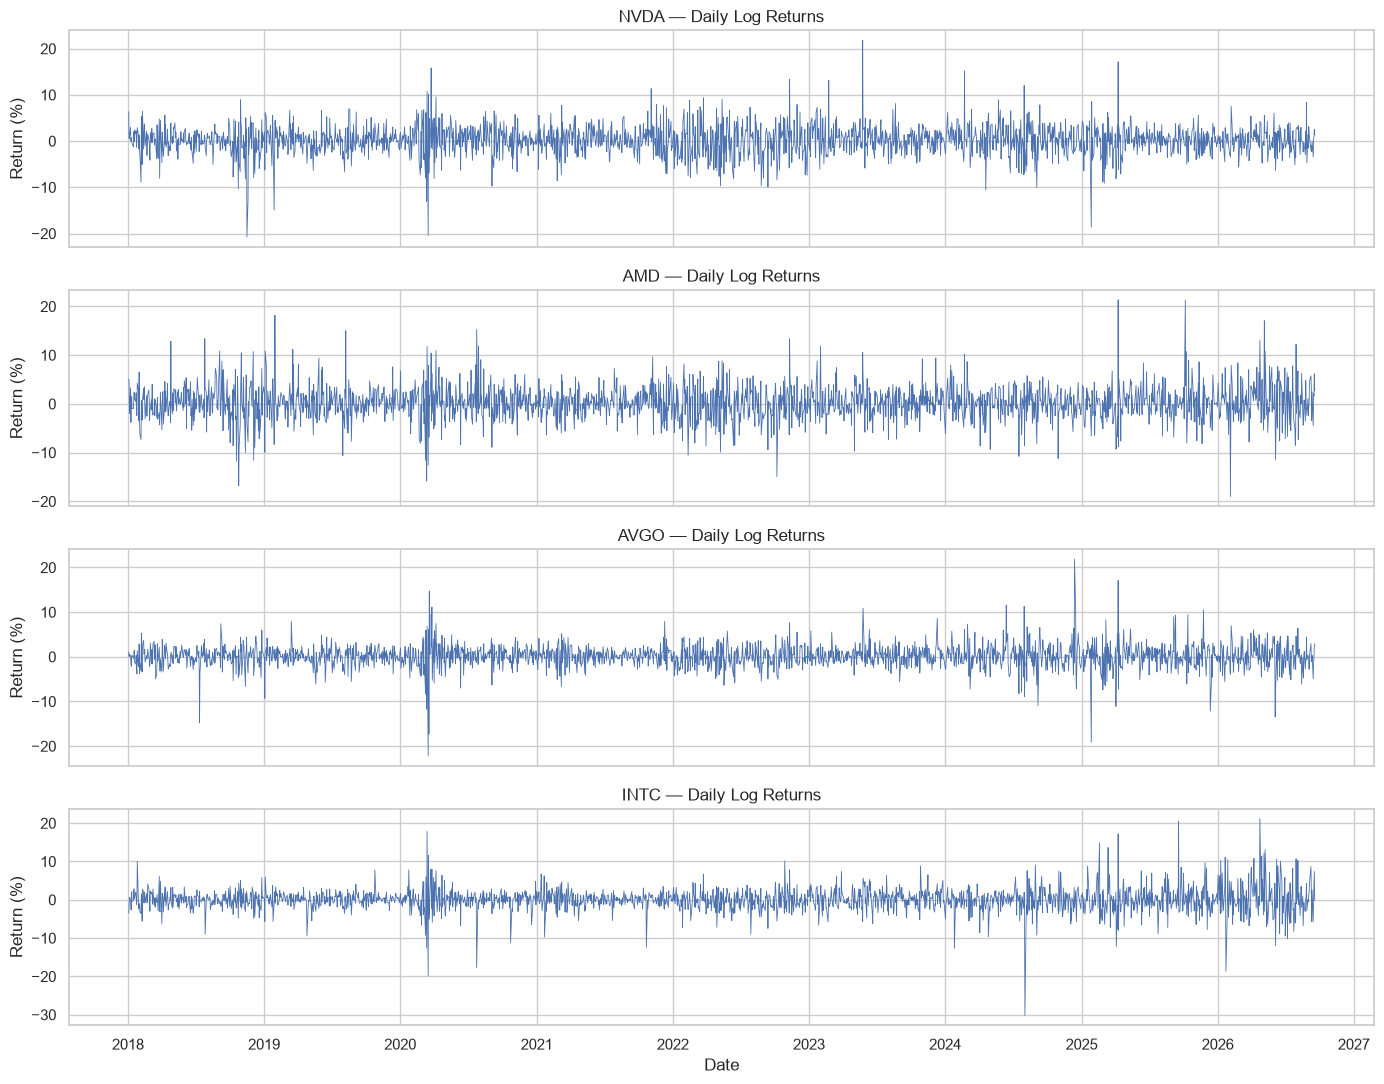

In [4]:

fig, axes = plt.subplots(nrows=4,ncols=1,figsize=(14, 11),sharex=True)

for ax, ticker in zip(axes, TICKERS):
    ax.plot(log_returns.index,log_returns[ticker],linewidth=0.6)
    ax.set_title(f"{ticker} — Daily Log Returns")
    ax.set_ylabel("Return (%)")

plt.xlabel("Date")
plt.tight_layout()
plt.show()

### 1.4 — Stylized facts and ARCH effects
Skewness and excess kurtosis describe distribution shape. The Jarque–Bera test checks unconditional normality, while the ARCH-LM test looks for dependence in squared return shocks.

In [5]:

diagnostic_results = []

for ticker in TICKERS:

    returns = log_returns[ticker].dropna()

    # Jarque-Bera normality test
    jb_stat, jb_pvalue = jarque_bera(returns)

    # ARCH-LM test with 10 lags
    arch_lm, arch_pvalue, _, _ = het_arch(
        returns - returns.mean(),
        nlags=10
    )

    diagnostic_results.append({
        "Ticker": ticker,
        "Mean (%)": returns.mean(),
        "Std (%)": returns.std(),
        "Skewness": returns.skew(),
        "Excess Kurtosis": returns.kurt(),
        "JB p-value": jb_pvalue,
        "ARCH-LM p-value": arch_pvalue
    })

diagnostics = pd.DataFrame(
    diagnostic_results
).set_index("Ticker")

display(diagnostics.round(5))

c:\Users\zedax\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,Mean (%),Std (%),Skewness,Excess Kurtosis,JB p-value,ARCH-LM p-value
Ticker,,,,,,
NVDA,0.17411,3.17038,-0.17564,4.72688,0.0,0.0
AMD,0.17960,3.54696,0.21951,3.45880,0.0,0.0
AVGO,0.12939,2.62623,-0.23654,9.83914,0.0,0.0
INTC,0.04640,3.05489,-0.16283,10.85319,0.0,0.0


**Interpretation.** All four equities display positive excess kurtosis, rejection of unconditional normality, and very small ARCH-LM p-values in the saved sample. This supports modeling *time-varying conditional variance*. The next plot illustrates the autocorrelation of squared returns.

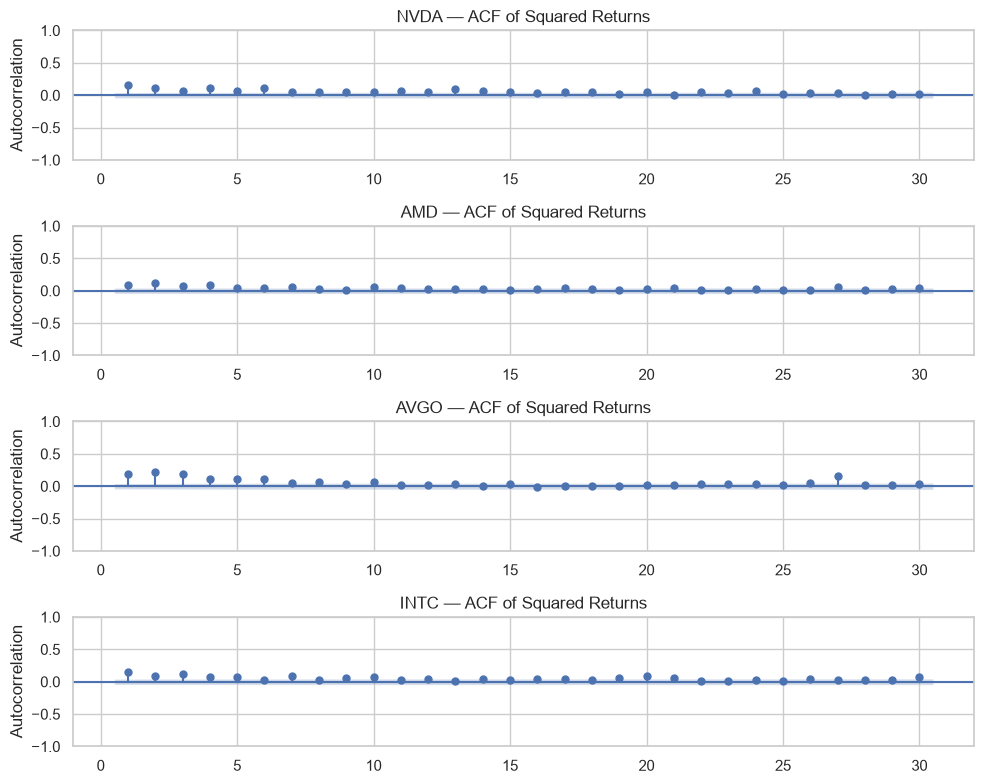

In [6]:

fig, axes = plt.subplots(4, 1,figsize=(10, 8))

for ax, ticker in zip(axes, TICKERS):
    squared_returns = log_returns[ticker] ** 2
    plot_acf(squared_returns,lags=30,ax=ax,zero=False,alpha=0.05)
    ax.set_title(f"{ticker} — ACF of Squared Returns")
    ax.set_ylabel("Autocorrelation")

plt.tight_layout()
plt.show()

### 1.5 — Gaussian GARCH(1,1) and maximum likelihood

\[\sigma_t^2=\omega+\alpha\varepsilon_{t-1}^2+\beta\sigma_{t-1}^2\]

Here, \(\omega\) is the baseline variance component, \(\alpha\) reflects the response to recent shocks, and \(\beta\) captures persistence in previously estimated variance. The `arch` package estimates the parameters by **maximum likelihood**. For this specification, \(\alpha+\beta\) summarizes volatility persistence.

In [7]:

# Gaussian GARCH(1,1) — Maximum Likelihood Estimation

garch_models = {}
garch_results = []

for ticker in TICKERS:

    returns = log_returns[ticker].dropna()

    model = arch_model(
        returns,
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False
    )

    # Maximum Likelihood Estimation
    fitted = model.fit(disp="off")

    garch_models[ticker] = fitted

    params = fitted.params

    omega = params["omega"]
    alpha = params["alpha[1]"]
    beta = params["beta[1]"]

    garch_results.append({
        "Ticker": ticker,
        "Omega": omega,
        "Alpha": alpha,
        "Beta": beta,
        "Persistence": alpha + beta,
        "Log-Likelihood": fitted.loglikelihood,
        "AIC": fitted.aic,
        "BIC": fitted.bic,
        "Convergence": fitted.convergence_flag
    })

garch_summary = pd.DataFrame(
    garch_results
).set_index("Ticker")

display(garch_summary.round(4))

# Full estimation results for NVIDIA
print("\nNVIDIA — GARCH(1,1) MLE Summary")
print(garch_models["NVDA"].summary())

,Omega,Alpha,Beta,Persistence,Log-Likelihood,AIC,BIC,Convergence
Ticker,,,,,,,,
NVDA,0.4688,0.1103,0.8479,0.9581,-5496.1296,11000.2592,11023.0240,0
AMD,1.1589,0.0840,0.8243,0.9084,-5807.6600,11623.3201,11646.0849,0
AVGO,0.2050,0.0952,0.8809,0.9761,-5028.6622,10065.3243,10088.0891,0
INTC,0.3873,0.0822,0.8787,0.9609,-5353.9400,10715.8799,10738.6447,0



NVIDIA — GARCH(1,1) MLE Summary
                     Constant Mean - GARCH Model Results                      
Dep. Variable:                   NVDA   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -5496.13
Distribution:                  Normal   AIC:                           11000.3
Method:            Maximum Likelihood   BIC:                           11023.0
                                        No. Observations:                 2189
Date:                Sun, Oct 18 2026   Df Residuals:                     2188
Time:                        20:27:55   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.2440  6.032e-02     

**Finding — Volatility persistence.** Estimated persistence (α + β) ranges from **0.908 for AMD** to **0.976 for AVGO** (NVDA: 0.958; INTC: 0.961). Volatility shocks therefore tend to fade gradually in this sample. The following figure compares the fitted *in-sample* conditional volatility with the magnitude of observed returns; it is not an out-of-sample forecast.

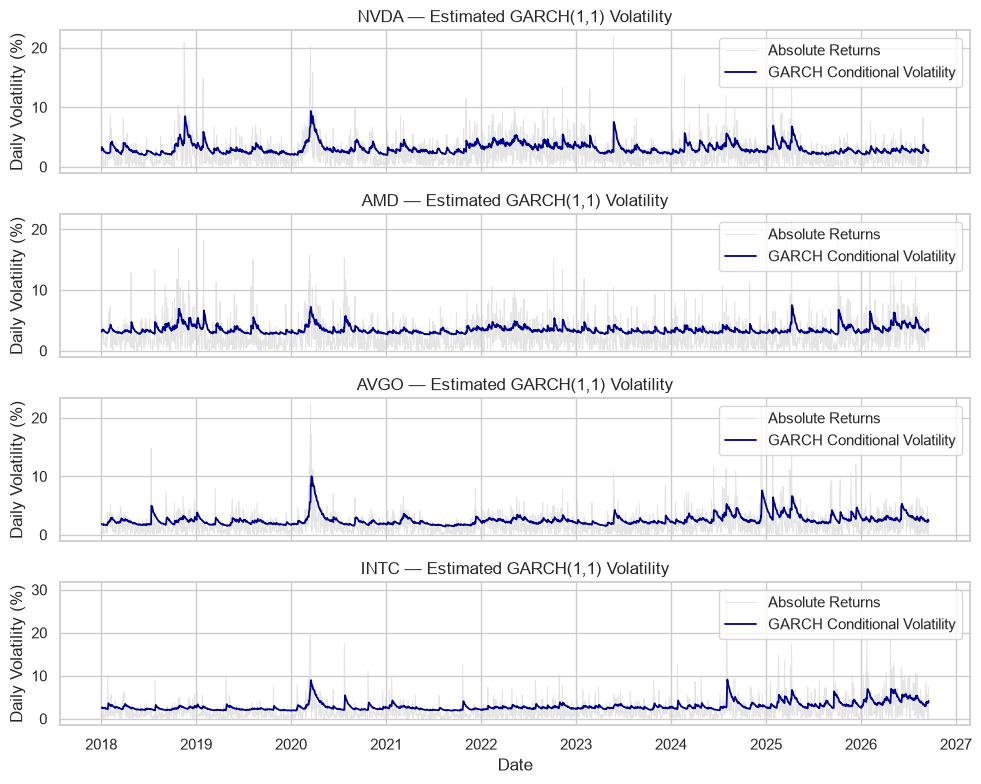

In [8]:

# GARCH(1,1) — Conditional Volatility Visualization

fig, axes = plt.subplots(nrows=4,ncols=1,figsize=(10, 8),sharex=True)

for ax, ticker in zip(axes, TICKERS):

    fitted = garch_models[ticker]

    # Estimated daily conditional volatility (%)
    conditional_vol = fitted.conditional_volatility

    # Absolute daily log returns (%)
    abs_returns = log_returns[ticker].abs()
    ax.plot(abs_returns.index,abs_returns,color="lightgray",alpha=0.6,linewidth=0.7,label="Absolute Returns")
    ax.plot(conditional_vol.index,conditional_vol,color="darkblue",linewidth=1.3,label="GARCH Conditional Volatility")
    ax.set_title(f"{ticker} — Estimated GARCH(1,1) Volatility")
    ax.set_ylabel("Daily Volatility (%)")
    ax.legend(loc="upper right")

plt.xlabel("Date")
plt.tight_layout()
plt.show()

### 1.6 — Checking the fitted model
We test the squared standardized residuals for remaining ARCH dependence and inspect residual normality. A successful baseline should remove most of the obvious volatility clustering, even if returns remain heavy-tailed.

In [9]:

residual_results = []

for ticker in TICKERS:

    fitted = garch_models[ticker]

    # Standardized residuals
    z = fitted.std_resid.dropna()

    # ARCH-LM test
    arch_stat, arch_p, _, _ = het_arch(z, nlags=10)

    # Ljung-Box test on squared standardized residuals
    lb = acorr_ljungbox(
        z**2,
        lags=[10],
        return_df=True
    )

    # Normality test
    jb = jarque_bera(z)

    residual_results.append({
        "Ticker": ticker,
        "ARCH-LM p-value": arch_p,
        "Ljung-Box p-value": lb["lb_pvalue"].iloc[0],
        "JB p-value": jb.pvalue,
        "Residual Kurtosis": z.kurt()
    })

residual_diagnostics = pd.DataFrame(
    residual_results
).set_index("Ticker")

display(residual_diagnostics.round(5))

c:\Users\zedax\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,ARCH-LM p-value,Ljung-Box p-value,JB p-value,Residual Kurtosis
Ticker,,,,
NVDA,0.92190,0.92529,0.0,4.64501
AMD,0.90438,0.90847,0.0,3.35436
AVGO,0.83343,0.81714,0.0,6.02120
INTC,0.99123,0.99095,0.0,12.23340


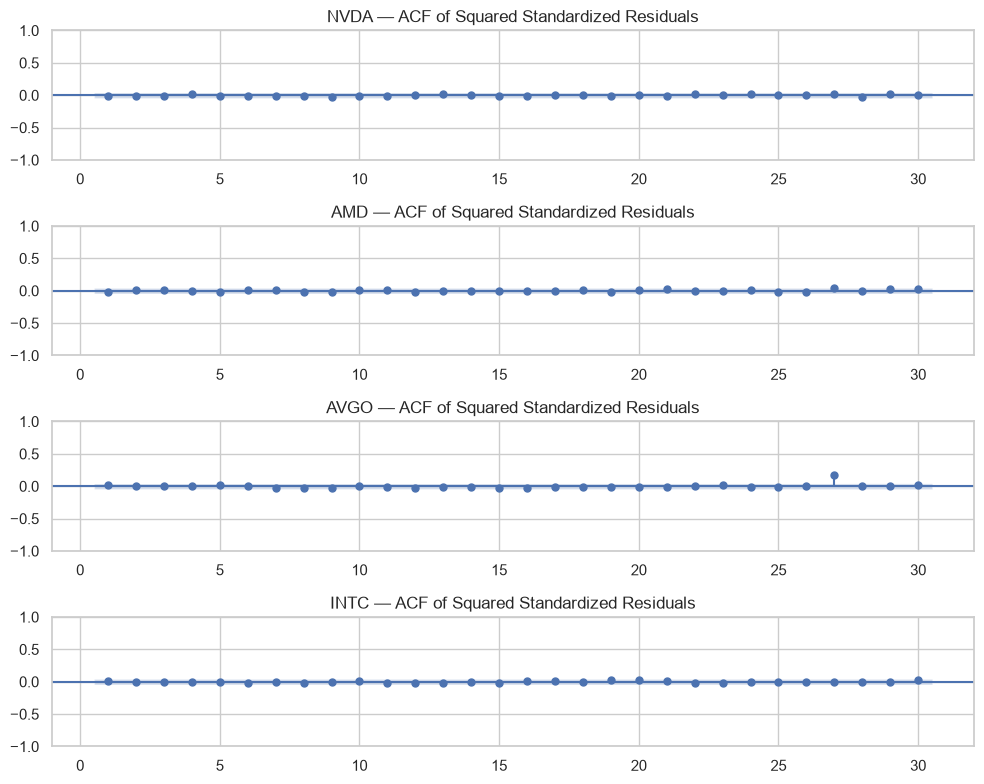

In [10]:

fig, axes = plt.subplots(4, 1, figsize=(10, 8))

for ax, ticker in zip(axes, TICKERS):

    z = garch_models[ticker].std_resid.dropna()
    plot_acf(z**2,lags=30,ax=ax,zero=False,alpha=0.05)
    ax.set_title(f"{ticker} — ACF of Squared Standardized Residuals")

plt.tight_layout()
plt.show()

**Finding — Baseline adequacy.** The standardized-residual ARCH-LM p-values are high across all four stocks (approximately **0.83–0.99**), so the selected tests do not detect remaining ARCH effects at those lags. Residual normality is still rejected. The baseline captures volatility dynamics, but Gaussian shocks may be too restrictive.

---
## Stage 2 — Asymmetry and Heavy Tails

### 2.1 — EGARCH and GJR-GARCH
Standard GARCH reacts symmetrically to positive and negative shocks of the same magnitude. **EGARCH** and **GJR-GARCH** allow the response to differ by shock sign. We compare their in-sample fit using AIC/BIC and examine the asymmetry parameter (γ).

In [11]:

# Stage 2 — EGARCH and GJR-GARCH estimation

asymmetric_models = {}
comparison_results = []

for ticker in TICKERS:

    returns = log_returns[ticker].dropna()

    # Include existing GARCH baseline
    baseline = garch_models[ticker]

    comparison_results.append({
        "Ticker": ticker,
        "Model": "GARCH",
        "AIC": baseline.aic,
        "BIC": baseline.bic,
        "Gamma": np.nan,
        "Gamma p-value": np.nan,
        "Convergence": baseline.convergence_flag
    })

    specifications = {
        "EGARCH": {"vol": "EGARCH"},
        "GJR-GARCH": {"vol": "GARCH"}
    }

    for name, spec in specifications.items():

        model = arch_model(
            returns,
            mean="Constant",
            vol=spec["vol"],
            p=1,
            o=1,
            q=1,
            dist="normal",
            rescale=False
        )

        fitted = model.fit(disp="off")

        asymmetric_models[(ticker, name)] = fitted

        comparison_results.append({
            "Ticker": ticker,
            "Model": name,
            "AIC": fitted.aic,
            "BIC": fitted.bic,
            "Gamma": fitted.params.get("gamma[1]", np.nan),
            "Gamma p-value": fitted.pvalues.get(
                "gamma[1]", np.nan
            ),
            "Convergence": fitted.convergence_flag
        })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        ["Ticker", "AIC"]
    ).round(4)
)


,Ticker,Model,AIC,BIC,Gamma,Gamma p-value,Convergence
5,AMD,GJR-GARCH,11618.6127,11647.0687,0.0553,0.1585,0
4,AMD,EGARCH,11620.7338,11649.1898,-0.0258,0.3334,0
3,AMD,GARCH,11623.3201,11646.0849,NaN,NaN,0
6,AVGO,GARCH,10065.3243,10088.0891,NaN,NaN,0
8,AVGO,GJR-GARCH,10067.2494,10095.7054,0.0052,0.8935,0
7,AVGO,EGARCH,10070.1745,10098.6305,-0.0107,0.7378,0
10,INTC,EGARCH,10675.5044,10703.9604,0.0280,0.3368,0
11,INTC,GJR-GARCH,10709.9761,10738.4321,-0.0472,0.2745,0
9,INTC,GARCH,10715.8799,10738.6447,NaN,NaN,0
1,NVDA,EGARCH,10955.0779,10983.5339,-0.0722,0.0051,0


**Finding — Shock asymmetry.** NVIDIA shows a statistically significant asymmetric response under both Gaussian specifications: **EGARCH γ = −0.0722 (p = 0.0051)** and **GJR-GARCH γ = 0.1396 (p = 0.0352)**. The fitted signs are consistent with a stronger response to negative shocks. Equivalent evidence is weaker for AMD, AVGO, and INTC.

### 2.2 — Gaussian versus Student-t innovations
Financial returns often have more extreme observations than a Gaussian distribution implies. Student-t innovations allow heavier tails, controlled by a degrees-of-freedom parameter (ν). We evaluate fit, not forecasts, in this step.

In [12]:

# Gaussian vs Student-t Innovations

distribution_models = {}
distribution_results = []

specifications = {
    "GARCH": ("GARCH", 0),
    "EGARCH": ("EGARCH", 1),
    "GJR-GARCH": ("GARCH", 1)
}

for ticker in TICKERS:

    returns = log_returns[ticker].dropna()

    for name, (vol_type, o) in specifications.items():

        # Existing Gaussian model
        gaussian = (
            garch_models[ticker]
            if name == "GARCH"
            else asymmetric_models[(ticker, name)]
        )

        # Student-t model
        model = arch_model(
            returns,
            mean="Constant",
            vol=vol_type,
            p=1,
            o=o,
            q=1,
            dist="t",
            rescale=False
        )

        student_t = model.fit(disp="off")

        distribution_models[(ticker, name, "t")] = student_t

        for dist, fitted in [
            ("Gaussian", gaussian),
            ("Student-t", student_t)
        ]:

            distribution_results.append({
                "Ticker": ticker,
                "Model": name,
                "Distribution": dist,
                "AIC": fitted.aic,
                "BIC": fitted.bic,
                "Nu": fitted.params.get("nu", np.nan),
                "Convergence": fitted.convergence_flag
            })

distribution_df = pd.DataFrame(distribution_results)

display(
    distribution_df.sort_values(
        ["Ticker", "AIC"]
    ).round(4)
)


,Ticker,Model,Distribution,AIC,BIC,Nu,Convergence
9,AMD,EGARCH,Student-t,11407.9363,11442.0835,4.6436,0
11,AMD,GJR-GARCH,Student-t,11410.3747,11444.5219,4.6394,0
7,AMD,GARCH,Student-t,11411.2878,11439.7438,4.6330,0
10,AMD,GJR-GARCH,Gaussian,11618.6127,11647.0687,NaN,0
8,AMD,EGARCH,Gaussian,11620.7338,11649.1898,NaN,0
6,AMD,GARCH,Gaussian,11623.3201,11646.0849,NaN,0
15,AVGO,EGARCH,Student-t,9755.9184,9790.0656,4.4609,0
17,AVGO,GJR-GARCH,Student-t,9761.8704,9796.0176,4.4384,0
13,AVGO,GARCH,Student-t,9768.6858,9797.1418,4.4526,0
12,AVGO,GARCH,Gaussian,10065.3243,10088.0891,NaN,0


**Finding — Heavy tails.** **EGARCH–Student-t has the lowest AIC for all four stocks**. BIC also prefers it for NVDA, AVGO, and INTC; the exception is AMD, where **GARCH–Student-t** has the lowest BIC. This is compelling in-sample evidence for heavier-tailed innovations — but AIC and BIC alone cannot establish forecasting superiority.

---
## Stage 3 — Out-of-Sample Volatility Forecasting

### 3.1 — Chronological evaluation design
We reserve **2025–September 2026** as the test period and use earlier observations for initial GARCH estimation. Randomly shuffling financial time series would leak future information into the past.

In [13]:

# Stage 3 — Chronological Train/Test Split

TRAIN_END = "2024-12-31"
TEST_START = "2025-01-01"

train_returns = log_returns.loc[:TRAIN_END].copy()
test_returns = log_returns.loc[TEST_START:].copy()

# Validate chronological split
assert not train_returns.empty
assert not test_returns.empty
assert train_returns.index.max() < test_returns.index.min()

split_summary = pd.DataFrame({
    "Asset": TICKERS,
    "Train Observations": [
        train_returns[t].count() for t in TICKERS
    ],
    "Test Observations": [
        test_returns[t].count() for t in TICKERS
    ],
    "Train End": [train_returns.index.max().date()] * 4,
    "Test Start": [test_returns.index.min().date()] * 4
})

display(split_summary)

print("Training period:",
      train_returns.index.min().date(),
      "to", train_returns.index.max().date())

print("Testing period:",
      test_returns.index.min().date(),
      "to", test_returns.index.max().date())


,Asset,Train Observations,Test Observations,Train End,Test Start
0,NVDA,1760,429,2024-12-31,2025-01-02
1,AMD,1760,429,2024-12-31,2025-01-02
2,AVGO,1760,429,2024-12-31,2025-01-02
3,INTC,1760,429,2024-12-31,2025-01-02


Training period: 2018-01-03 to 2024-12-31
Testing period: 2025-01-02 to 2026-09-18


### 3.2 — One-day-ahead variance forecasts for NVDA
The forecast for each test date uses only information available before that date. GARCH parameters are re-estimated every **21 trading days**, while the volatility state is updated with new observations in between. First, we compare Gaussian GARCH with Student-t EGARCH on NVDA.

In [14]:

# Stage 3 — Expanding-window one-step-ahead forecasts

TICKER = "NVDA"
REFIT_EVERY = 21

forecast_specs = {
    "GARCH-Gaussian": {
        "vol": "GARCH", "p": 1, "o": 0,
        "q": 1, "dist": "normal"
    },
    "EGARCH-Student-t": {
        "vol": "EGARCH", "p": 1, "o": 1,
        "q": 1, "dist": "t"
    }
}

forecast_results = pd.DataFrame(
    index=test_returns.index
)

forecast_results["Actual Return"] = test_returns[TICKER]

for name, spec in forecast_specs.items():

    predictions = []
    fitted_params = None

    for i, date in enumerate(test_returns.index):

        # Historical returns strictly before forecast date
        history = log_returns.loc[
            log_returns.index < date, TICKER
        ].dropna()

        model = arch_model(
            history,
            mean="Constant",
            vol=spec["vol"],
            p=spec["p"],
            o=spec["o"],
            q=spec["q"],
            dist=spec["dist"],
            rescale=False
        )

        # Re-estimate parameters every 21 trading days
        if i % REFIT_EVERY == 0:

            fitted = model.fit(disp="off")

            if fitted.convergence_flag != 0:
                raise RuntimeError(
                    f"{name} failed to converge on {date}"
                )

            fitted_params = fitted.params.copy()

        # Update volatility using latest available data
        fixed = model.fix(fitted_params)

        # Forecast variance for the next trading day
        forecast = fixed.forecast(
            horizon=1,
            reindex=False
        )

        variance = forecast.variance.iloc[-1, 0]

        if not np.isfinite(variance) or variance <= 0:
            raise ValueError("Invalid variance forecast")

        predictions.append(variance)

    forecast_results[f"{name} Variance"] = predictions
    forecast_results[f"{name} Volatility"] = np.sqrt(
        predictions
    )

print("Out-of-sample forecasts completed.")
print("Forecast observations:", len(forecast_results))

display(forecast_results.head().round(4))
display(forecast_results.tail().round(4))


Out-of-sample forecasts completed.
Forecast observations: 429


,Actual Return,GARCH-Gaussian Variance,GARCH-Gaussian Volatility,EGARCH-Student-t Variance,EGARCH-Student-t Volatility
Date,,,,,
2025-01-02,2.9496,6.2038,2.4907,7.2526,2.6931
2025-01-03,4.3575,6.5478,2.5589,7.0921,2.6631
2025-01-06,3.3756,7.8918,2.8092,7.4138,2.7228
2025-01-07,-6.4186,8.2490,2.8721,7.3716,2.7151
2025-01-08,-0.0214,12.4005,3.5214,12.8872,3.5899


,Actual Return,GARCH-Gaussian Variance,GARCH-Gaussian Volatility,EGARCH-Student-t Variance,EGARCH-Student-t Volatility
Date,,,,,
2026-09-14,-3.4156,7.2708,2.6964,7.9497,2.8195
2026-09-15,0.5719,8.1138,2.8485,9.7684,3.1254
2026-09-16,0.8121,7.3632,2.7135,8.5078,2.9168
2026-09-17,2.5114,6.7499,2.5981,7.5313,2.7443
2026-09-18,1.3270,6.7595,2.5999,7.1937,2.6821


### 3.3 — Forecast accuracy: MSE and QLIKE

We compare forecasts of next-day variance with squared daily returns, \(r_t^2\), as a **noisy ex-post proxy**, rather than a directly observed variance. For forecasts \(\hat\sigma_t^2\):

\[\mathrm{MSE}=\operatorname{mean}[(r_t^2-\hat\sigma_t^2)^2]\]

\[\mathrm{QLIKE}=\operatorname{mean}[\log(\hat\sigma_t^2)+r_t^2/\hat\sigma_t^2]\]

**Lower is better** for both metrics. The comparison includes a simple 21-day historical variance benchmark.

In [15]:

# Stage 3 — Out-of-Sample Forecast Evaluation

# Squared returns as a noisy realized variance proxy
realized_variance = forecast_results["Actual Return"] ** 2

# Historical variance benchmark: previous 21 trading days
historical_variance = (
    log_returns[TICKER]
    .shift(1)
    .rolling(window=21)
    .var()
)

evaluation = pd.DataFrame(index=forecast_results.index)

evaluation["Realized Variance"] = realized_variance

for name in forecast_specs:
    evaluation[name] = forecast_results[f"{name} Variance"]

evaluation["Historical-21D"] = historical_variance.reindex(
    evaluation.index
)

evaluation = evaluation.dropna()

# Evaluate models
performance = []

for model_name in evaluation.columns.drop("Realized Variance"):

    actual = evaluation["Realized Variance"]
    predicted = evaluation[model_name]

    if not np.isfinite(predicted).all() or (predicted <= 0).any():
        raise ValueError(f"Invalid forecasts: {model_name}")

    mse = np.mean((actual - predicted) ** 2)

    qlike = np.mean(
        np.log(predicted) + actual / predicted
    )

    performance.append({
        "Model": model_name,
        "MSE": mse,
        "QLIKE": qlike
    })

performance_df = pd.DataFrame(performance)

performance_df["MSE Rank"] = (
    performance_df["MSE"].rank().astype(int)
)

performance_df["QLIKE Rank"] = (
    performance_df["QLIKE"].rank().astype(int)
)

display(
    performance_df.sort_values("QLIKE").round(4)
)

print("Evaluation observations:", len(evaluation))


,Model,MSE,QLIKE,MSE Rank,QLIKE Rank
1,EGARCH-Student-t,570.6550,2.9757,1,1
0,GARCH-Gaussian,582.7151,3.0033,2,2
2,Historical-21D,608.2416,3.0408,3,3


Evaluation observations: 429


**Finding — NVDA forecast accuracy.** Across **429 test days**, EGARCH–Student-t leads with **MSE 570.65 / QLIKE 2.9757**; Gaussian GARCH scores **582.71 / 3.0033**, and Historical-21D **608.24 / 3.0408**. The improvement is economically relevant as a forecasting comparison, not evidence of statistically significant superiority.

### 3.4 — Visualizing the NVDA forecasts
Daily predictions reveal how promptly each model responds to shocks. The smoothed panel below is **descriptive only**: smoothing uses ex-post data and is not a tradable forecast series.

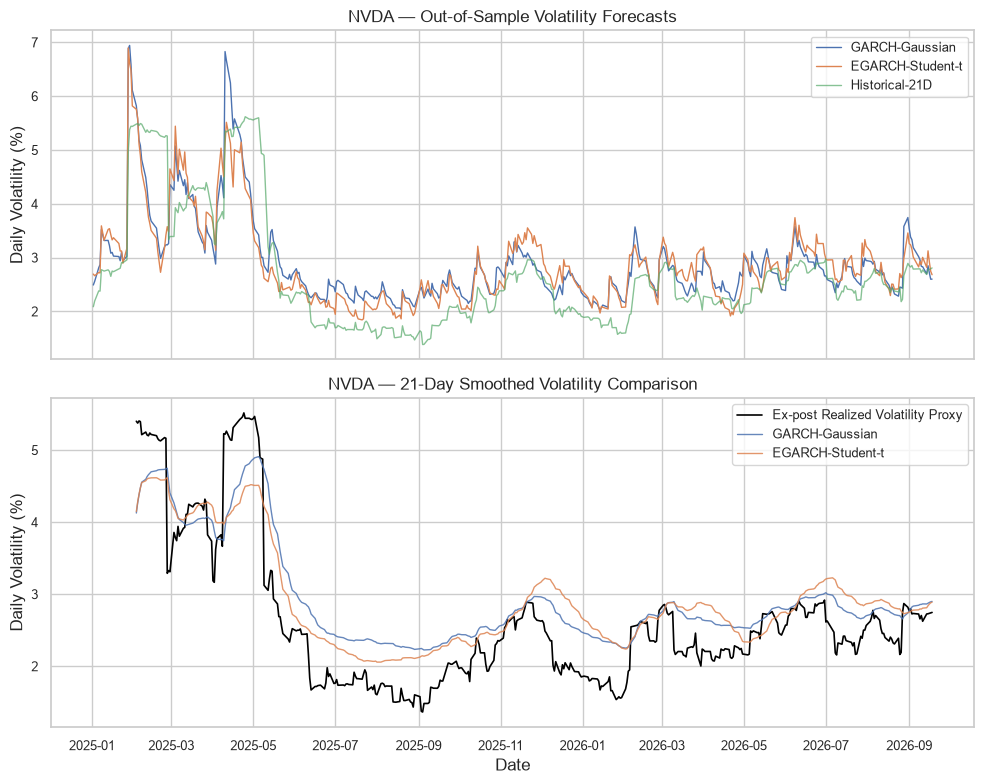

In [16]:
# Stage 3 — Volatility Forecast Visualization (smaller figure)

fig, axes = plt.subplots(2, 1,figsize=(10, 8),sharex=True)

dates = evaluation.index

# Daily volatility forecasts
axes[0].plot(dates,np.sqrt(evaluation["GARCH-Gaussian"]),label="GARCH-Gaussian",linewidth=1.0)
axes[0].plot(dates,np.sqrt(evaluation["EGARCH-Student-t"]),label="EGARCH-Student-t",linewidth=1.0)
axes[0].plot(dates,np.sqrt(evaluation["Historical-21D"]),label="Historical-21D",linewidth=1.0,alpha=0.7)

axes[0].set_title("NVDA — Out-of-Sample Volatility Forecasts")
axes[0].set_ylabel("Daily Volatility (%)")
axes[0].legend(fontsize=9)
axes[0].tick_params(axis="both", labelsize=9)

# Smoothed volatility comparison (21-day)
window = 21

realized_vol = np.sqrt(
    evaluation["Realized Variance"].rolling(window).mean()
)

garch_vol = np.sqrt(
    evaluation["GARCH-Gaussian"].rolling(window).mean()
)

egarch_vol = np.sqrt(
    evaluation["EGARCH-Student-t"].rolling(window).mean()
)

axes[1].plot(dates,realized_vol,label="Ex-post Realized Volatility Proxy",color="black",linewidth=1.2)
axes[1].plot(dates,garch_vol,label="GARCH-Gaussian",linewidth=1.0,alpha=0.85)
axes[1].plot(dates,egarch_vol,label="EGARCH-Student-t",linewidth=1.0,alpha=0.85)
axes[1].set_title("NVDA — 21-Day Smoothed Volatility Comparison")
axes[1].set_ylabel("Daily Volatility (%)")
axes[1].set_xlabel("Date")
axes[1].legend(fontsize=9)
axes[1].tick_params(axis="both", labelsize=9)

plt.tight_layout()
plt.show()

### 3.5 — Extending forecasts to AMD, AVGO and INTC
To test whether the NVDA result generalizes, we repeat the *same* forecasting procedure for the remaining three equities, retaining identical test dates and error metrics.

In [17]:

# Stage 3 — Multi-Asset Volatility Forecasting

assets_to_run = ["AMD", "AVGO", "INTC"]

# Keep previously calculated NVDA forecasts
all_forecasts = {"NVDA": forecast_results.copy()}

for ticker in assets_to_run:

    print(f"Processing {ticker}...")

    asset_forecasts = pd.DataFrame(
        index=test_returns.index
    )

    asset_forecasts["Actual Return"] = test_returns[ticker]

    for name, spec in forecast_specs.items():

        predictions = []
        fitted_params = None

        for i, date in enumerate(test_returns.index):

            # Use only information available before date
            history = log_returns.loc[
                log_returns.index < date, ticker
            ].dropna()

            model = arch_model(
                history,
                mean="Constant",
                vol=spec["vol"],
                p=spec["p"],
                o=spec["o"],
                q=spec["q"],
                dist=spec["dist"],
                rescale=False
            )

            # Refit every 21 trading days
            if i % REFIT_EVERY == 0:

                fitted = model.fit(disp="off")

                if fitted.convergence_flag != 0:
                    raise RuntimeError(
                        f"{ticker} {name}: convergence failed"
                    )

                fitted_params = fitted.params.copy()

            fixed = model.fix(fitted_params)

            forecast = fixed.forecast(
                horizon=1,
                reindex=False
            )

            variance = float(
                forecast.variance.iloc[-1, 0]
            )

            if not np.isfinite(variance) or variance <= 0:
                raise ValueError("Invalid variance forecast")

            predictions.append(variance)

        asset_forecasts[f"{name} Variance"] = predictions

    all_forecasts[ticker] = asset_forecasts

# Evaluate all four assets
results = []

for ticker, df in all_forecasts.items():

    actual_var = df["Actual Return"] ** 2

    historical_var = (
        log_returns[ticker]
        .shift(1)
        .rolling(21)
        .var()
        .reindex(df.index)
    )

    evaluation_data = pd.DataFrame({
        "Actual": actual_var,
        "GARCH-Gaussian": df["GARCH-Gaussian Variance"],
        "EGARCH-Student-t": df["EGARCH-Student-t Variance"],
        "Historical-21D": historical_var
    }).dropna()

    for model_name in [
        "GARCH-Gaussian",
        "EGARCH-Student-t",
        "Historical-21D"
    ]:

        y = evaluation_data["Actual"]
        pred = evaluation_data[model_name]

        if not np.isfinite(pred).all() or (pred <= 0).any():
            raise ValueError(f"Invalid forecasts: {ticker}, {model_name}")

        results.append({
            "Ticker": ticker,
            "Model": model_name,
            "MSE": np.mean((y - pred) ** 2),
            "QLIKE": np.mean(np.log(pred) + y / pred)
        })

multi_asset_comparison = pd.DataFrame(results)

display(multi_asset_comparison.sort_values(["Ticker", "QLIKE"]).round(4))
print("Multi-asset forecast evaluation completed.")

Processing AMD...
Processing AVGO...
Processing INTC...


,Ticker,Model,MSE,QLIKE
3,AMD,GARCH-Gaussian,1834.3431,3.8354
4,AMD,EGARCH-Student-t,1828.3635,3.8482
5,AMD,Historical-21D,1924.1409,3.9655
7,AVGO,EGARCH-Student-t,808.8752,3.4330
6,AVGO,GARCH-Gaussian,831.6472,3.4613
8,AVGO,Historical-21D,874.3485,3.5418
10,INTC,EGARCH-Student-t,2135.0108,4.1003
11,INTC,Historical-21D,2192.9134,4.1339
9,INTC,GARCH-Gaussian,2282.3819,4.3053
1,NVDA,EGARCH-Student-t,570.6550,2.9757


Multi-asset forecast evaluation completed.


**Finding — Econometric benchmark.** Among the GARCH-family forecasting models evaluated, EGARCH–Student-t has the **lowest MSE for all four equities** and the lowest QLIKE for **three of four**. For AMD, Gaussian GARCH has the lowest QLIKE. Results therefore depend partly on the chosen loss function.

---
## Stage 4 — 1D-CNN: A Deep Learning Benchmark

### 4.1 — Learning from historical returns
We train a small **1D convolutional network** to predict next-day variance from rolling windows of 30 observations. Each window contains three features: return, absolute return and squared return. The training target is the following day's squared return.

- **Training:** 2018–2023
- **Validation:** 2024 (early stopping)
- **Testing:** 2025–September 2026 (never used to tune the network)

Feature scaling is fitted on training-period observations only, preventing look-ahead leakage.

In [18]:

# Stage 4 — 1D-CNN Data Preparation

LOOKBACK = 30
CNN_TRAIN_END = "2023-12-31"
CNN_VAL_END = "2024-12-31"

cnn_data = {}
dataset_summary = []

for ticker in TICKERS:

    returns = log_returns[ticker].dropna().sort_index()

    # Three historical features
    features = np.column_stack([
        returns.values,
        np.abs(returns.values),
        returns.values ** 2
    ])

    # Fit normalization using training data only
    train_mask = returns.index <= CNN_TRAIN_END

    train_mean = features[train_mask].mean(axis=0)
    train_std = features[train_mask].std(axis=0)

    train_std[train_std == 0] = 1.0

    scaled_features = (
        features - train_mean
    ) / train_std

    # Sliding windows: previous 30 days -> next-day squared return
    X, y, dates = [], [], []

    for i in range(LOOKBACK, len(returns)):

        X.append(
            scaled_features[i - LOOKBACK:i]
        )

        y.append(returns.iloc[i] ** 2)
        dates.append(returns.index[i])

    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32).reshape(-1, 1)
    dates = pd.DatetimeIndex(dates)

    train_idx = dates <= CNN_TRAIN_END

    val_idx = (
        (dates > CNN_TRAIN_END) &
        (dates <= CNN_VAL_END)
    )

    test_idx = dates > CNN_VAL_END

    cnn_data[ticker] = {
        "X_train": X[train_idx],
        "y_train": y[train_idx],
        "X_val": X[val_idx],
        "y_val": y[val_idx],
        "X_test": X[test_idx],
        "y_test": y[test_idx],
        "test_dates": dates[test_idx]
    }

    assert dates[test_idx].equals(test_returns.index)

    dataset_summary.append({
        "Ticker": ticker,
        "Training": train_idx.sum(),
        "Validation": val_idx.sum(),
        "Testing": test_idx.sum(),
        "Input Shape": str(X.shape[1:])
    })

cnn_summary = pd.DataFrame(dataset_summary)

display(cnn_summary)

print("\nCNN datasets prepared successfully.")


,Ticker,Training,Validation,Testing,Input Shape
0,NVDA,1478,252,429,"(30, 3)"
1,AMD,1478,252,429,"(30, 3)"
2,AVGO,1478,252,429,"(30, 3)"
3,INTC,1478,252,429,"(30, 3)"



CNN datasets prepared successfully.


### 4.2 — CNN architecture
Two small Conv1D layers with pooling extract local return patterns. A dense network maps those patterns to **one positive variance estimate** using a Softplus output. This deliberately simple architecture serves as a benchmark rather than an attempt to maximize neural-network complexity.

In [19]:

# Stage 4 — 1D-CNN Architecture

import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam

# Reproducibility
tf.keras.utils.set_random_seed(42)

# NVIDIA training data
X_train = cnn_data["NVDA"]["X_train"]
y_train = cnn_data["NVDA"]["y_train"]

# Build CNN
cnn_model = Sequential([
    Input(shape=(LOOKBACK, 3)),

    Conv1D(
        filters=32,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    MaxPooling1D(pool_size=2),

    Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    GlobalAveragePooling1D(),

    Dense(32, activation="relu"),

    Dropout(0.2),

    # Positive variance prediction
    Dense(1, activation="softplus")
])

# Compile model
cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Display architecture
cnn_model.summary()

print("\nTraining input shape:", X_train.shape)
print("Training target shape:", y_train.shape)
print("TensorFlow version:", tf.__version__)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 30, 32)         │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 15, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 15, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,641 (33.75 KB)

 Trainable params: 8,641 (33.75 KB)

 Non-trainable params: 0 (0.00 B)


Training input shape: (1478, 30, 3)
Training target shape: (1478, 1)
TensorFlow version: 2.21.0


### 4.3 — Training on NVDA
We monitor validation MSE and restore the weights from the best validation epoch using early stopping. The test set is held out until training is finished.


Best Epoch: 44
Best Validation MSE: 476.0496


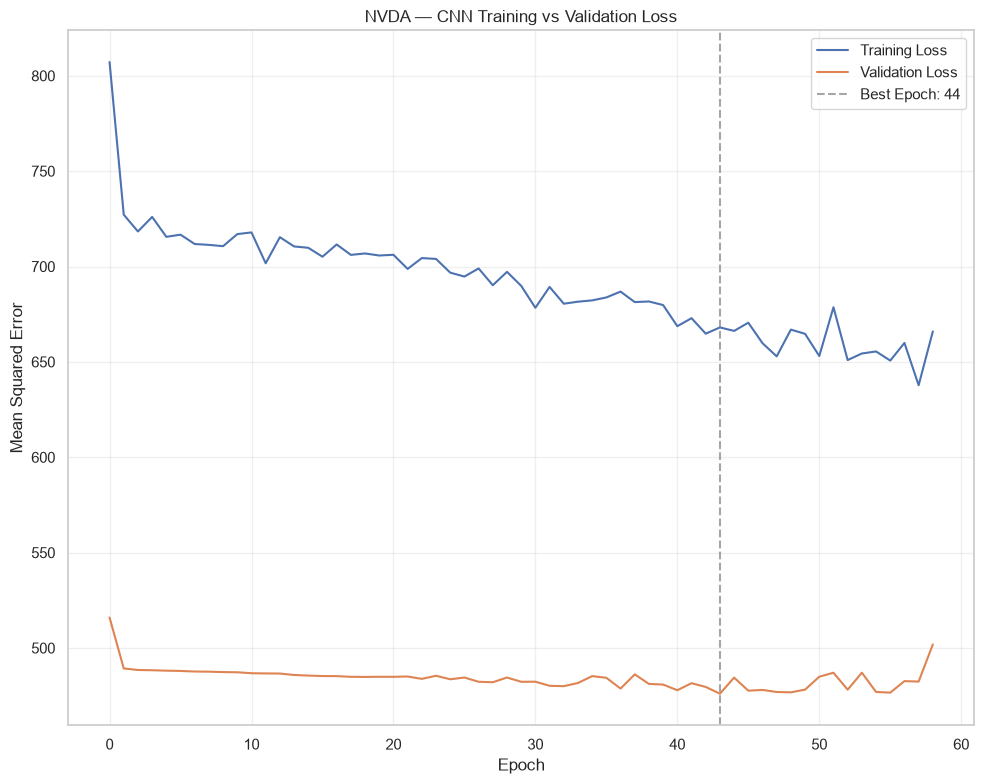

In [20]:

# Stage 4 — CNN Training and Learning Curves

from tensorflow.keras.callbacks import EarlyStopping

# NVIDIA dataset
data = cnn_data["NVDA"]

X_train = data["X_train"]
y_train = data["y_train"]

X_val = data["X_val"]
y_val = data["y_val"]

# Early stopping to reduce overfitting
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

# Train CNN
history = cnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    shuffle=False,
    verbose=0
)

# Training summary
best_epoch = np.argmin(history.history["val_loss"]) + 1

print(f"\nBest Epoch: {best_epoch}")
print(f"Best Validation MSE: {min(history.history['val_loss']):.4f}")

# Plot learning curves
fig, ax = plt.subplots(figsize=(10, 8))
ax.plot(history.history["loss"],label="Training Loss",linewidth=1.5)
ax.plot(history.history["val_loss"],label="Validation Loss",linewidth=1.5)
ax.axvline(best_epoch - 1,color="gray",linestyle="--",alpha=0.7,label=f"Best Epoch: {best_epoch}")
ax.set_title("NVDA — CNN Training vs Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean Squared Error")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.4 — NVDA: CNN versus econometric forecasts
The CNN, GARCH and historical benchmark are evaluated on the **same 429 dates** with exactly the same loss functions. This is a comparison of forecasting methods, not predictions of return direction.

In [21]:

# Stage 4 — CNN vs GARCH Forecast Evaluation

# NVIDIA test dataset
data = cnn_data["NVDA"]

X_test = data["X_test"]
test_dates = data["test_dates"]

# Predict next-day conditional variance
cnn_predictions = cnn_model.predict(
    X_test,
    verbose=0
).flatten()

# Check matching test dates
assert test_dates.equals(forecast_results.index)

# Create comparison dataset
cnn_evaluation = pd.DataFrame(index=test_dates)

cnn_evaluation["Realized Variance"] = (
    forecast_results["Actual Return"] ** 2
)

cnn_evaluation["CNN-1D"] = cnn_predictions

cnn_evaluation["GARCH-Gaussian"] = (
    forecast_results["GARCH-Gaussian Variance"]
)

cnn_evaluation["EGARCH-Student-t"] = (
    forecast_results["EGARCH-Student-t Variance"]
)

# Historical volatility benchmark
cnn_evaluation["Historical-21D"] = (
    log_returns["NVDA"]
    .shift(1)
    .rolling(21)
    .var()
    .reindex(test_dates)
)

# Validate predictions
assert cnn_evaluation.notna().all().all()

forecast_columns = cnn_evaluation.columns.drop(
    "Realized Variance"
)

assert np.isfinite(cnn_evaluation.to_numpy()).all()
assert (cnn_evaluation[forecast_columns] > 0).all().all()

# Calculate MSE and QLIKE
actual = cnn_evaluation["Realized Variance"]

results = []

for model_name in forecast_columns:

    predicted = cnn_evaluation[model_name]

    mse = np.mean((actual - predicted) ** 2)

    qlike = np.mean(
        np.log(predicted) + actual / predicted
    )

    results.append({
        "Model": model_name,
        "MSE": mse,
        "QLIKE": qlike
    })

cnn_comparison = pd.DataFrame(results)

cnn_comparison["MSE Rank"] = (
    cnn_comparison["MSE"].rank().astype(int)
)

cnn_comparison["QLIKE Rank"] = (
    cnn_comparison["QLIKE"].rank().astype(int)
)

display(
    cnn_comparison.sort_values("QLIKE").round(4)
)

print("Test observations:", len(cnn_evaluation))
print("Best model by QLIKE:",
      cnn_comparison.loc[
          cnn_comparison["QLIKE"].idxmin(), "Model"
      ])


,Model,MSE,QLIKE,MSE Rank,QLIKE Rank
2,EGARCH-Student-t,570.6550,2.9757,1,1
1,GARCH-Gaussian,582.7151,3.0033,3,2
0,CNN-1D,572.6679,3.0194,2,3
3,Historical-21D,608.2416,3.0408,4,4


Test observations: 429
Best model by QLIKE: EGARCH-Student-t


**Finding — NVDA CNN.** The CNN achieves **MSE 572.95**, slightly better than Gaussian GARCH (**582.71**), but worse than EGARCH–Student-t (**570.65**). Its **QLIKE 3.0391** is also worse than both GARCH variants. A competitive MSE does not imply consistently superior risk forecasts.

### 4.5 — How do CNN forecasts respond to volatility shocks?
In the daily and smoothed charts, the CNN appears less responsive to some sharp increases in NVDA volatility, particularly early in 2025. This visual impression helps interpret, but does not replace, the numeric scores.

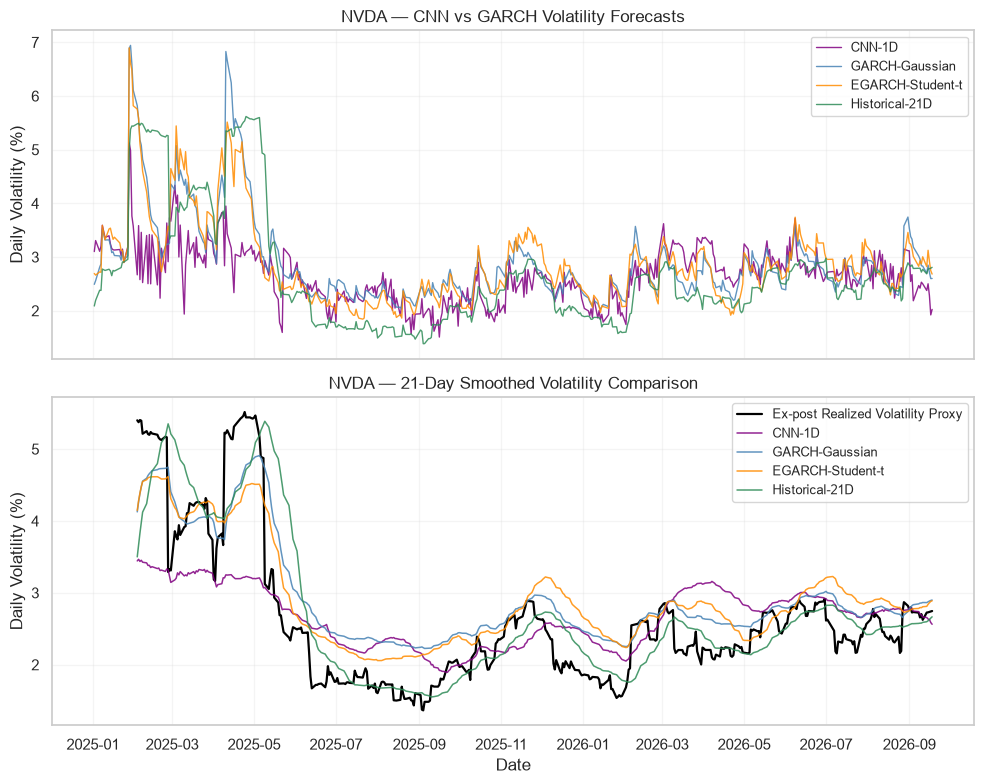

In [22]:

# Stage 4 — CNN vs GARCH Forecast Visualization
fig, axes = plt.subplots(2, 1,figsize=(10, 8),sharex=True)
models = ["CNN-1D","GARCH-Gaussian","EGARCH-Student-t","Historical-21D"]

colors = ["purple", "steelblue", "darkorange", "seagreen"]

# 1. Daily volatility forecasts
for model, color in zip(models, colors):
    axes[0].plot(
        cnn_evaluation.index,
        np.sqrt(cnn_evaluation[model]),
        label=model,
        color=color,
        linewidth=1.0,
        alpha=0.85
    )

axes[0].set_title("NVDA — CNN vs GARCH Volatility Forecasts")
axes[0].set_ylabel("Daily Volatility (%)")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.2)

# 2. Smoothed volatility comparison
window = 21

realized_vol = np.sqrt(
    cnn_evaluation["Realized Variance"]
    .rolling(window).mean()
)

axes[1].plot(cnn_evaluation.index,realized_vol,color="black",linewidth=1.6,label="Ex-post Realized Volatility Proxy")

for model, color in zip(models, colors):

    smoothed_vol = np.sqrt(
        cnn_evaluation[model]
        .rolling(window).mean()
    )

    axes[1].plot(cnn_evaluation.index,smoothed_vol,label=model,color=color,linewidth=1.1,alpha=0.85)

axes[1].set_title("NVDA — 21-Day Smoothed Volatility Comparison")
axes[1].set_ylabel("Daily Volatility (%)")
axes[1].set_xlabel("Date")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 4.6 — Training the same CNN on all four equities
We keep the neural-network architecture, time split and training procedure fixed across assets. This avoids turning the test period into a hyperparameter search.

In [23]:

# Stage 4 — Multi-Asset CNN Training & Evaluation

assets_to_train = ["AMD", "AVGO", "INTC"]

cnn_models = {"NVDA": cnn_model}
cnn_predictions_by_asset = {
    "NVDA": cnn_evaluation["CNN-1D"].copy()
}

def build_cnn():
    model = Sequential([
        Input(shape=(LOOKBACK, 3)),
        Conv1D(32, 3, activation="relu", padding="same"),
        MaxPooling1D(2),
        Conv1D(64, 3, activation="relu", padding="same"),
        GlobalAveragePooling1D(),
        Dense(32, activation="relu"),
        Dropout(0.2),
        Dense(1, activation="softplus")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )
    return model


# Train separate CNN for each stock
for ticker in assets_to_train:

    print(f"\nTraining CNN — {ticker}")

    tf.keras.utils.set_random_seed(42)

    data = cnn_data[ticker]

    model = build_cnn()

    callback = EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    )

    history_asset = model.fit(
        data["X_train"],
        data["y_train"],
        validation_data=(
            data["X_val"],
            data["y_val"]
        ),
        epochs=100,
        batch_size=32,
        callbacks=[callback],
        shuffle=False,
        verbose=0
    )

    predictions = model.predict(
        data["X_test"],
        verbose=0
    ).flatten()

    dates = data["test_dates"]

    assert dates.equals(all_forecasts[ticker].index)

    cnn_predictions_by_asset[ticker] = pd.Series(
        predictions,
        index=dates,
        name="CNN-1D"
    )

    cnn_models[ticker] = model

    best_epoch = (
        np.argmin(history_asset.history["val_loss"]) + 1
    )

    print(f"Best epoch: {best_epoch}")
    print(f"Test forecasts: {len(predictions)}")


# Evaluate all models on identical dates
comparison_rows = []

for ticker in TICKERS:

    df = all_forecasts[ticker]

    evaluation_asset = pd.DataFrame({
        "Actual": df["Actual Return"] ** 2,
        "CNN-1D": cnn_predictions_by_asset[ticker],
        "GARCH-Gaussian": df["GARCH-Gaussian Variance"],
        "EGARCH-Student-t": df["EGARCH-Student-t Variance"],
        "Historical-21D": (
            log_returns[ticker]
            .shift(1)
            .rolling(21)
            .var()
            .reindex(df.index)
        )
    }).dropna()

    assert len(evaluation_asset) == len(df)
    assert np.isfinite(evaluation_asset.to_numpy()).all()

    actual = evaluation_asset["Actual"]

    for name in [
        "CNN-1D",
        "GARCH-Gaussian",
        "EGARCH-Student-t",
        "Historical-21D"
    ]:

        predicted = evaluation_asset[name]

        assert (predicted > 0).all()

        mse = np.mean((actual - predicted) ** 2)

        qlike = np.mean(
            np.log(predicted) + actual / predicted
        )

        comparison_rows.append({
            "Ticker": ticker,
            "Model": name,
            "MSE": mse,
            "QLIKE": qlike
        })


final_comparison = pd.DataFrame(comparison_rows)
display(final_comparison.sort_values(["Ticker", "QLIKE"]).round(4))
print("\nMulti-Asset CNN evaluation completed.")


Training CNN — AMD
Best epoch: 2
Test forecasts: 429

Training CNN — AVGO
Best epoch: 12
Test forecasts: 429

Training CNN — INTC
Best epoch: 2
Test forecasts: 429


,Ticker,Model,MSE,QLIKE
5,AMD,GARCH-Gaussian,1834.3431,3.8354
6,AMD,EGARCH-Student-t,1828.3635,3.8482
4,AMD,CNN-1D,1852.2790,3.8778
7,AMD,Historical-21D,1924.1409,3.9655
8,AVGO,CNN-1D,787.6793,3.2890
10,AVGO,EGARCH-Student-t,808.8752,3.4330
9,AVGO,GARCH-Gaussian,831.6472,3.4613
11,AVGO,Historical-21D,874.3485,3.5418
14,INTC,EGARCH-Student-t,2135.0108,4.1003
15,INTC,Historical-21D,2192.9134,4.1339



Multi-Asset CNN evaluation completed.


**Finding — Broadcom stands out.** On **AVGO**, the CNN leads with **MSE 787.68 / QLIKE 3.2890**, ahead of EGARCH–Student-t (**808.87 / 3.4330**). It does not lead overall on NVDA, AMD or INTC. In the cross-stock plots, the CNN response to large spikes is especially subdued for NVDA and INTC; its stronger result for AVGO is asset-specific.

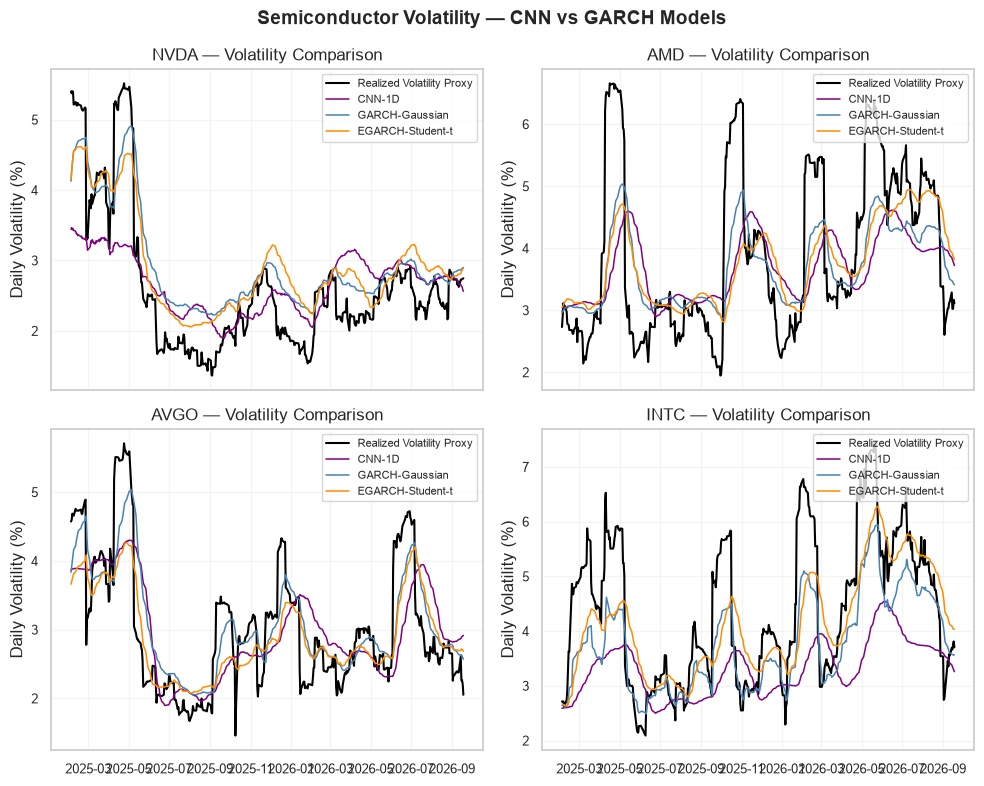

In [24]:

# Stage 4 — Multi-Asset Volatility Visualization

fig, axes = plt.subplots(2, 2,figsize=(10, 8),sharex=True)
window = 21

for ax, ticker in zip(axes.flat, TICKERS):

    df = all_forecasts[ticker]

    # Actual squared returns (ex-post proxy)
    actual_var = df["Actual Return"] ** 2

    # CNN and GARCH variance forecasts
    comparison = pd.DataFrame({
        "Realized": actual_var,
        "CNN": cnn_predictions_by_asset[ticker],
        "GARCH": df["GARCH-Gaussian Variance"],
        "EGARCH": df["EGARCH-Student-t Variance"]
    })

    # 21-day smoothed volatility
    smoothed = np.sqrt(
        comparison.rolling(window).mean()
    )
    
    ax.plot(smoothed.index,smoothed["Realized"],color="black",linewidth=1.5,label="Realized Volatility Proxy")
    ax.plot(smoothed.index,smoothed["CNN"],color="purple",linewidth=1.1,label="CNN-1D")
    ax.plot(smoothed.index,smoothed["GARCH"],color="steelblue",linewidth=1.1,label="GARCH-Gaussian")
    ax.plot(smoothed.index,smoothed["EGARCH"],color="darkorange",linewidth=1.1,label="EGARCH-Student-t")
    ax.set_title(f"{ticker} — Volatility Comparison")
    ax.set_ylabel("Daily Volatility (%)")
    ax.grid(alpha=0.2)
    ax.tick_params(axis="both", labelsize=9)
    ax.legend(fontsize=8, loc="upper right")

fig.suptitle("Semiconductor Volatility — CNN vs GARCH Models",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 4.7 — Improvement relative to the historical benchmark
The MSE levels cannot be compared directly across stocks because their volatility scales differ. We therefore present **within-stock MSE skill**, calculated as \(100(1-\mathrm{MSE}_{model}/\mathrm{MSE}_{Historical})\). For QLIKE we show the absolute loss reduction relative to Historical-21D.

Positive values indicate improvement over the historical benchmark.

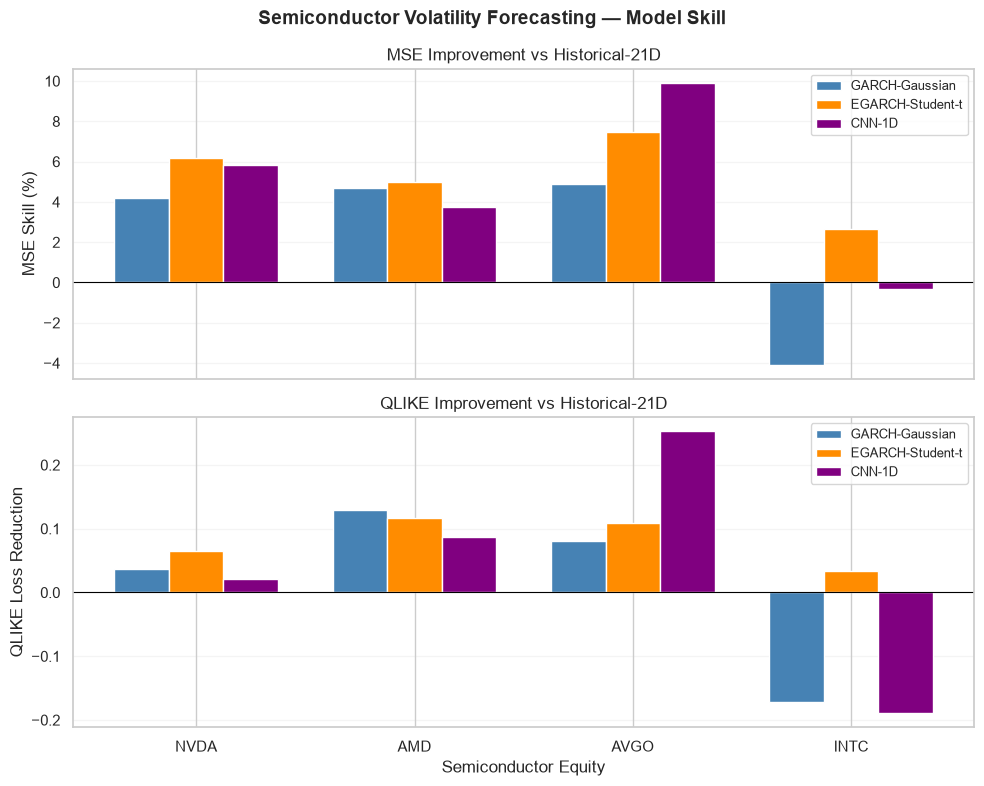

Figure saved: outputs\figures\model_skill_comparison.png

MSE Skill (%)


Model,GARCH-Gaussian,EGARCH-Student-t,CNN-1D
Ticker,,,
NVDA,4.20,6.18,5.85
AMD,4.67,4.98,3.73
AVGO,4.88,7.49,9.91
INTC,-4.08,2.64,-0.33



QLIKE Loss Reduction


Model,GARCH-Gaussian,EGARCH-Student-t,CNN-1D
Ticker,,,
NVDA,0.0375,0.0651,0.0214
AMD,0.1301,0.1173,0.0878
AVGO,0.0804,0.1088,0.2528
INTC,-0.1714,0.0336,-0.1893


In [25]:

# Stage 4 — Forecast Improvement vs Historical Benchmark

models = ["GARCH-Gaussian","EGARCH-Student-t","CNN-1D"]

mse_table = final_comparison.pivot(
    index="Ticker",
    columns="Model",
    values="MSE"
).loc[TICKERS]

qlike_table = final_comparison.pivot(
    index="Ticker",
    columns="Model",
    values="QLIKE"
).loc[TICKERS]

# MSE improvement percentage
mse_skill = (
    1 - mse_table[models].div(
        mse_table["Historical-21D"],
        axis=0
    )
) * 100

# QLIKE improvement (lower loss is better)
qlike_gain = qlike_table[models].rsub(
    qlike_table["Historical-21D"],
    axis=0
)

# Visualization
fig, axes = plt.subplots(2, 1,figsize=(10, 8),sharex=True)

colors = ["steelblue", "darkorange", "purple"]
x = np.arange(len(TICKERS))
width = 0.25

for i, (model, color) in enumerate(zip(models, colors)):

    positions = x + (i - 1) * width
    
    axes[0].bar(positions,mse_skill[model],width,label=model,color=color)
    axes[1].bar(positions,qlike_gain[model],width,label=model,color=color)

axes[0].set_title("MSE Improvement vs Historical-21D")
axes[0].set_ylabel("MSE Skill (%)")
axes[1].set_title("QLIKE Improvement vs Historical-21D")
axes[1].set_ylabel("QLIKE Loss Reduction")
axes[1].set_xlabel("Semiconductor Equity")

for ax in axes:
    ax.axhline(0, color="black", linewidth=0.8)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(fontsize=9)

axes[1].set_xticks(x)
axes[1].set_xticklabels(TICKERS)

fig.suptitle(
    "Semiconductor Volatility Forecasting — Model Skill",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

# Save this figure once for the research report / README.
from pathlib import Path
figures_dir = Path("outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)
figure_path = figures_dir / "model_skill_comparison.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")

plt.show()
print("Figure saved:", figure_path)

print("\nMSE Skill (%)")
display(mse_skill.round(2))

print("\nQLIKE Loss Reduction")
display(qlike_gain.round(4))

**Finding — Model skill.** The CNN improves on Historical-21D MSE by **9.91% for AVGO**, compared with **5.80% for NVDA** and **3.73% for AMD**; it slightly trails the benchmark for INTC (**−0.33%**). EGARCH–Student-t improves on the historical baseline in MSE and QLIKE for all four equities in the overall test period.

---
## Stage 5 — Forecast Stability

### 5.1 — Comparing 2025 with partial 2026
A strong overall result can be driven by a limited market regime. We therefore review the same MSE and QLIKE scores separately for calendar 2025 and the available part of 2026. This is a **descriptive robustness check**, not another validation set.

In [26]:

# Stage 4 — Forecast Stability: 2025 vs 2026

annual_results = []
models = ["CNN-1D","GARCH-Gaussian","EGARCH-Student-t","Historical-21D"]

for ticker in TICKERS:

    df = all_forecasts[ticker]

    comparison = pd.DataFrame({
        "Actual": df["Actual Return"] ** 2,
        "CNN-1D": cnn_predictions_by_asset[ticker],
        "GARCH-Gaussian": df["GARCH-Gaussian Variance"],
        "EGARCH-Student-t": df["EGARCH-Student-t Variance"],
        "Historical-21D": (
            log_returns[ticker]
            .shift(1)
            .rolling(21)
            .var()
            .reindex(df.index)
        )
    }).dropna()

    for year in [2025, 2026]:

        period = comparison[
            comparison.index.year == year
        ]

        actual = period["Actual"]

        for model in models:

            predicted = period[model]

            mse = np.mean(
                (actual - predicted) ** 2
            )

            qlike = np.mean(
                np.log(predicted) + actual / predicted
            )

            annual_results.append({
                "Ticker": ticker,
                "Year": year,
                "Model": model,
                "MSE": mse,
                "QLIKE": qlike
            })

annual_df = pd.DataFrame(annual_results)

# Identify annual winners
summary_rows = []

for (ticker, year), group in annual_df.groupby(
    ["Ticker", "Year"], sort=True
):

    best_mse = group.loc[group["MSE"].idxmin()]
    best_qlike = group.loc[group["QLIKE"].idxmin()]

    cnn = group[group["Model"] == "CNN-1D"].iloc[0]
    benchmark = group[
        group["Model"] == "Historical-21D"
    ].iloc[0]

    cnn_skill = (
        1 - cnn["MSE"] / benchmark["MSE"]
    ) * 100

    summary_rows.append({
        "Ticker": ticker,
        "Year": year,
        "Best MSE Model": best_mse["Model"],
        "Best QLIKE Model": best_qlike["Model"],
        "CNN MSE Skill (%)": cnn_skill
    })

annual_summary = pd.DataFrame(summary_rows)

display(annual_summary.round(2))

print("\nAnnual forecasting comparison completed.")


,Ticker,Year,Best MSE Model,Best QLIKE Model,CNN MSE Skill (%)
0,AMD,2025,GARCH-Gaussian,GARCH-Gaussian,4.79
1,AMD,2026,EGARCH-Student-t,EGARCH-Student-t,2.13
2,AVGO,2025,CNN-1D,CNN-1D,11.42
3,AVGO,2026,GARCH-Gaussian,GARCH-Gaussian,0.51
4,INTC,2025,EGARCH-Student-t,Historical-21D,0.35
5,INTC,2026,EGARCH-Student-t,EGARCH-Student-t,-0.88
6,NVDA,2025,EGARCH-Student-t,EGARCH-Student-t,6.42
7,NVDA,2026,Historical-21D,CNN-1D,-2.15



Annual forecasting comparison completed.


**Finding — Performance changes over time.** AVGO's CNN MSE skill declines from **+11.42% (2025)** to **+0.51% (partial 2026)**, when Gaussian GARCH leads in both losses. NVDA's CNN moves from **+6.56% to −4.80%**. EGARCH–Student-t has the best annual MSE for INTC in both periods, but Historical-21D has the best 2025 QLIKE there. **Model rankings are not stable across all stocks or years.**

### 5.2 — Save compact numeric results
The following cell exports the overall and annual tables as CSV files. The written report is deliberately kept in Markdown, not constructed line-by-line in Python.

In [27]:
# Export forecast comparison tables (research text is in Markdown above)
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

final_comparison.to_csv(output_dir / "overall_forecast_results.csv", index=False)
annual_df.to_csv(output_dir / "annual_forecast_results.csv", index=False)

print("Saved forecast results to:", output_dir.resolve())


Saved forecast results to: C:\Users\zedax\Desktop\Financial_Data_Science_Lab\semiconductors-GARCH\outputs


---
# Research Report — Discussion and Conclusions

## Research objective and approach

This study examines whether conventional conditional-volatility models and a lightweight convolutional neural network can forecast daily risk in semiconductor stocks. Four equities — NVDA, AMD, AVGO and INTC — are assessed on a common historical sample from 2018 through September 2026. We distinguish fitting a model to historical returns from forecasting genuinely unseen observations.

## Evidence from the return series

The daily returns exhibit volatility clustering, pronounced excess kurtosis and significant ARCH effects. These patterns support models that allow risk to change through time. The Gaussian GARCH(1,1) baseline produces substantial volatility persistence across the four stocks (approximately **0.91–0.98**). Diagnostics on standardized residuals suggest that the baseline removes much of the measured ARCH dependence, although heavy tails remain relevant.

Allowing for asymmetric shocks is particularly informative for **NVIDIA**: both EGARCH and GJR-GARCH detect a significant sign-dependent response under Gaussian innovations. Across assets, Student-t innovations substantially improve the in-sample information criteria. **EGARCH–Student-t has the lowest AIC for all four stocks**, though this finding should not be confused with out-of-sample predictive accuracy.

## Forecast comparison

We evaluate **429 one-step-ahead forecasts** from **2 January 2025 to 18 September 2026** against squared daily returns, using MSE and QLIKE. The historical 21-day variance provides a transparent reference. Model performance is summarized below from the saved run.

| Equity | Lowest MSE | Lowest QLIKE | Main observation |
|---|---|---|---|
| **NVDA** | EGARCH–Student-t | EGARCH–Student-t | CNN is close on MSE but weaker on QLIKE |
| **AMD** | EGARCH–Student-t | GARCH–Gaussian | Ranking depends on the loss function |
| **AVGO** | **1D-CNN** | **1D-CNN** | Best CNN result among the four stocks |
| **INTC** | EGARCH–Student-t | EGARCH–Student-t | CNN has difficulty with some major volatility spikes |

The **CNN adds predictive value selectively**, most notably for Broadcom. Its AVGO forecast reaches **MSE 787.68**, versus **808.87** for EGARCH–Student-t, and improves MSE by approximately **9.91%** relative to Historical-21D. Conversely, on INTC the CNN is slightly worse than the historical benchmark by MSE and substantially worse by QLIKE. There is therefore no basis for claiming that deep learning universally outperforms GARCH.

## Performance over time

The year-by-year breakdown gives an important qualification. The CNN's AVGO MSE advantage is concentrated in **2025**; its improvement over the historical baseline falls from **11.42%** in 2025 to **0.51%** in partial 2026, when Gaussian GARCH leads. For NVDA, the corresponding CNN skill shifts from **+6.56%** to **−4.80%**. **Forecast quality is dependent on both the asset and the market period.**

## Limitations and interpretation

Squared daily returns are a noisy proxy for latent volatility. The CNN is trained once with a single random seed, whereas GARCH parameters are periodically re-estimated during testing, so the comparison is not perfectly symmetric in model updating. The 2026 sample is incomplete, and differences in loss values are descriptive; no formal statistical-significance claim is made. Finally, none of these models is intended to predict whether the stock price will rise or fall.

## Conclusion

For this sample, **EGARCH with Student-t innovations is the most consistently competitive volatility-forecasting benchmark**. A simple 1D-CNN can outperform the econometric models for an individual semiconductor equity, but its performance is less consistent across assets and years. The principal finding is not that one methodology always wins; it is that **the usefulness of nonlinear deep learning depends on the underlying volatility dynamics and the evaluation period**. This makes careful out-of-sample comparison more informative than in-sample fit alone.